# Airline Review Analysis - Notebook 6: Aspect Based Sentiment Analysis

A single yes / no for a whole review hides a lot. A passenger can love the crew and still hate the delay. **Aspect based sentiment analysis (ABSA)** measures the opinion about each topic (aspect) separately.

Steps in this notebook:
1. split every review into small pieces (sentences and clauses)
2. find which topic each piece is about (using the word lists from Notebook 5)
3. measure the sentiment of each piece
4. combine the pieces into one sentiment per topic per review

Syllabus topics used here (Unit 3): opinion mining, affective lexicons, learning affective lexicons, aspect based sentiment analysis.

Input: `data/reviews_preprocessed.csv`, `data/topic_words.json`, `models/sentiment_model.joblib`, `data/train_test_split.csv`
Output: `data/aspect_segments.csv` and `data/aspect_reviews.csv`

## 1. Setup

In [1]:
import re
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download("wordnet", quiet=True)
nltk.download("vader_lexicon", quiet=True)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 120)

df = pd.read_csv("data/reviews_preprocessed.csv", parse_dates=["review_date"])
split = pd.read_csv("data/train_test_split.csv")
topic_words = json.load(open("data/topic_words.json"))

saved = joblib.load("models/sentiment_model.joblib")
tfidf, model = saved["tfidf"], saved["model"]

lemmatizer = WordNetLemmatizer()
sia = SentimentIntensityAnalyzer()
print(len(df), "reviews,", len(topic_words), "topics")

64331 reviews, 13 topics


## 2. Finding the topic of a piece of text

These are the same functions as in Notebook 5: they lowercase the text, expand short forms, lemmatize the words and check whether any topic word or phrase appears.

In [2]:
lemma_cache = {}
keep_as_is = {"ground"}

def get_lemma(word):
    if word in keep_as_is:
        return word
    if word not in lemma_cache:
        lemma = lemmatizer.lemmatize(word, pos="v")
        lemma_cache[word] = lemmatizer.lemmatize(lemma, pos="n")
    return lemma_cache[word]


def expand_contractions(text):
    text = text.replace("’", "'")
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"\b(did|does|do|was|were|is|are|would|could|should|have|has|had|can)nt\b", r"\1 not", text)
    return text


def to_lemmas(text):
    text = expand_contractions(text.lower())
    text = text.replace("on board", "onboard")
    text = re.sub(r"[^a-z\s]", " ", text)
    return [get_lemma(w) for w in text.split()]


def find_topics(text):
    lemmas = to_lemmas(text)
    lemma_set = set(lemmas)
    joined = " " + " ".join(lemmas) + " "
    found = []
    for topic, entry in topic_words.items():
        if any(w in lemma_set for w in entry["words"]) or any(" " + p + " " in joined for p in entry["phrases"]):
            found.append(topic)
    return found

find_topics("The cabin crew were lovely but the flight was delayed.")

['delay', 'cabin_crew']

## 3. Why one score per review is not enough

Here is a mixed review. The Notebook 4 model gave it a score of 0.73 (fairly positive), which hides the delay problem.

In [3]:
example = "The crew were lovely but the flight was delayed for five hours and we got no information."
print("score for the whole review:", round(model.predict_proba(tfidf.transform([example]))[0][1], 2))

score for the whole review: 0.73


## 4. Splitting reviews into pieces

First I split into sentences (at . ! ?), then I split sentences into clauses at words like "but", "however" and "although", and at semicolons. A piece like "the crew were lovely" then contains one opinion about one topic.

In [4]:
sentence_split = re.compile(r'(?<=[.!?])\s+(?=[A-Z0-9"“‘(])|\n+')
clause_split = re.compile(r";\s+|\s+[-–—]\s+|,?\s+(?:but|however|although|though|whereas)\s+", re.I)

for sentence in sentence_split.split(example):
    for clause in clause_split.split(sentence):
        print("-", clause)

- The crew were lovely
- the flight was delayed for five hours and we got no information.


Sometimes one clause mentions several topics in a list, such as "the crew were nice, the food was ok, the entertainment was poor". If a clause has two or more topics, I split it further at the commas so that every topic gets its own part.

In [5]:
def get_topic_pieces(text):
    # returns a list of (piece of text, topic) for one review
    results = []
    for sentence in sentence_split.split(text):
        for clause in clause_split.split(sentence):
            clause = clause.strip(" ,.-")
            if len(clause.split()) < 3:
                continue
            topics = find_topics(clause)
            if len(topics) >= 2:
                for part in re.split(r",\s+(?:and\s+)?", clause):
                    part = part.strip(" ,.-")
                    if len(part.split()) >= 2:
                        for topic in find_topics(part):
                            results.append((part, topic))
            else:
                for topic in topics:
                    results.append((clause, topic))
    return results


get_topic_pieces("The cabin crew were nice, the food was ok, the entertainment was poor. Check in took two hours.")

[('The cabin crew were nice', 'cabin_crew'),
 ('the food was ok', 'food'),
 ('the entertainment was poor', 'entertainment'),
 ('Check in took two hours', 'boarding_checkin')]

Now I apply it to all reviews (about half a minute).

In [6]:
rows = []
for review_id, text in zip(df.index, df["review_text"]):
    for piece, topic in get_topic_pieces(text):
        rows.append((review_id, topic, piece))

pieces = pd.DataFrame(rows, columns=["review_id", "topic", "text"])
print("topic pieces found:", len(pieces))
print("reviews with at least one topic:", pieces["review_id"].nunique(), "of", len(df))
pieces.sample(5, random_state=2)

topic pieces found: 392624
reviews with at least one topic: 62454 of 64331


,review_id,topic,text
370597,60458,ground_staff,ground staff totally unorganized
54335,9065,food,No entree /dessert on meal tray
6710,1356,food,"During the long-time flying, the food is good and bar is open to us, where we can stand and chat to kill the time"
376692,61381,seat,No one took responsibility for our welfare left on the hard seats of the airport until they were ready
316280,51597,ground_staff,"And when we were trying to rebook, the people standing at the counters would not take us, as 'they had to be free fo..."


## 5. Measuring the sentiment of each piece

I use two methods and compare them.

**Method A: VADER.** The ready-made sentiment dictionary from Notebook 4. Gives a score from -1 to +1.

**Method B: the learned lexicon.** The Logistic Regression model from Notebook 4 was trained on whole reviews, so it learned which words go with recommending and not recommending. I give it just the piece of text, and the output is the probability (0 to 1) that the text comes from a passenger who recommends the airline. A low value means negative sentiment and a high value means positive sentiment. This is the "learning an affective lexicon from data" idea from the syllabus.

In [7]:
pieces["vader"] = pieces["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
pieces["learned"] = model.predict_proba(tfidf.transform(pieces["text"]))[:, 1]

pieces = pieces.merge(split, on="review_id")      # adds whether the review was in the train or test part
pieces[["topic", "text", "vader", "learned"]].sample(8, random_state=5).round(2)

,topic,text,vader,learned
246711,cabin_crew,The tables are great and the cabin crew come and bring a table cloth before they bring the food,0.62,0.86
148016,cabin_crew,The service during the flight was very poor and the attitude of the cabin crew with passengers was really rude,-0.77,0.06
94298,food,The food was of a reasonable standard,0.00,0.73
348496,cancellation,Emirates cancelled it for Munich which led to a long wait at the airport until they eventually sorted it by reimburs...,-0.25,0.26
301625,boarding_checkin,Boarded the plane to find out that our seats were not together!,0.00,0.12
69454,delay,This morning we arrived at the airport in Udonthani at 07.40am to find out that the 09.15am flight to Bangkok had be...,-0.53,0.58
118505,boarding_checkin,After a very stressful wait at the gate I was the last passenger to get on,-0.56,0.15
220861,baggage,looking to checkin the extra bag and we are asked to pay $230,-0.10,0.10


Let me look at some short examples of problems that VADER does not understand but the learned model does.

In [8]:
tests = ["They lost my luggage", "The flight was delayed", "Our flight was cancelled", "The seat was comfortable"]
for t in tests:
    print(t, "| VADER:", sia.polarity_scores(t)["compound"], "| learned:", round(model.predict_proba(tfidf.transform([t]))[0][1], 2))

They lost my luggage | VADER: -0.3182 | learned: 0.02
The flight was delayed | VADER: -0.2263 | learned: 0.27
Our flight was cancelled | VADER: -0.25 | learned: 0.24
The seat was comfortable | VADER: 0.5106 | learned: 0.99


VADER gives only a weak negative score (about -0.2 to -0.3) to "delayed", "cancelled" and "lost luggage", because its dictionary was not made for airline problems, while the learned model clearly sees them as negative (scores of 0.02 to 0.27). In Notebook 7 I will measure which method agrees better with the passengers' own ratings.

One thing to keep in mind: the model was trained on 80% of the reviews, so for those reviews the scores can be slightly optimistic. The tables in this notebook use all reviews, but the check in Notebook 7 uses only the test reviews, which the model has never seen.

## 6. Choosing cut-offs for negative / neutral / positive

For the learned score I need cut-offs. Middle values are often neutral facts ("boarding started at 5 pm"), so I want a neutral zone. To pick the cut-offs I compare the labels with the 1 to 5 ratings that passengers gave to seat, crew, food, entertainment, ground service, WiFi and value for money. I only use the **training** reviews for this, so the test reviews stay untouched for the final check.

In [9]:
rating_columns = {"seat": "seat_comfort", "cabin_crew": "cabin_staff_service", "food": "food__beverages",
                  "entertainment": "inflight_entertainment", "ground_staff": "ground_service",
                  "wifi": "wifi__connectivity", "value_fees": "value_for_money"}

per_review = pieces.groupby(["review_id", "topic"])["learned"].mean().reset_index()

check = []
for topic, column in rating_columns.items():
    part = per_review[per_review["topic"] == topic].copy()
    part["rating"] = df.loc[part["review_id"], column].values
    check.append(part)
check = pd.concat(check).dropna(subset=["rating"])
check = check.merge(split, on="review_id")
check = check[(check["split"] == "train") & (check["rating"].isin([1, 2, 4, 5]))]   # clearly unhappy or happy

rows = []
for low, high in [(0.5, 0.5), (0.4, 0.6), (0.35, 0.65), (0.3, 0.7), (0.2, 0.8)]:
    labelled = (check["learned"] < low) | (check["learned"] >= high)
    predicted_positive = check.loc[labelled, "learned"] >= high
    actually_positive = check.loc[labelled, "rating"] >= 4
    rows.append({"negative below": low, "positive from": high,
                 "share labelled": round(labelled.mean(), 2),
                 "agreement with ratings": round((predicted_positive == actually_positive).mean(), 3)})
pd.DataFrame(rows)

,negative below,positive from,share labelled,agreement with ratings
0,0.50,0.50,1.00,0.839
1,0.40,0.60,0.84,0.886
2,0.35,0.65,0.75,0.904
3,0.30,0.70,0.67,0.921
4,0.20,0.80,0.49,0.948


A wider neutral zone gives higher agreement but labels fewer cases. I choose **0.35 and 0.65**: it labels about three quarters of the cases and agrees with the passengers' ratings about 90% of the time.

In [10]:
NEG_CUT, POS_CUT = 0.35, 0.65

def to_label(score):
    if score < NEG_CUT:
        return "negative"
    elif score >= POS_CUT:
        return "positive"
    return "neutral"

## 7. One score per topic per review

If a review has several pieces about the same topic, I take the average of their scores.

In [11]:
topic_scores = pieces.groupby(["review_id", "topic"]).agg(
    learned=("learned", "mean"),
    vader=("vader", "mean"),
    n_pieces=("text", "count"),
    split=("split", "first")).reset_index()

topic_scores["label"] = topic_scores["learned"].apply(to_label)
print(topic_scores.shape)
topic_scores.head()

(231583, 7)


,review_id,topic,learned,vader,n_pieces,split,label
0,0,communication,0.102772,0.141367,3,train,negative
1,0,delay,0.168482,0.126967,3,train,negative
2,1,cabin_crew,0.259969,0.000000,1,train,negative
3,1,communication,0.389180,-0.067433,3,train,neutral
4,1,delay,0.442031,-0.202300,1,train,neutral


## 8. Analysing a single review

A small function that shows the topics found in any review and the sentiment of each one.

In [12]:
def analyse_review(text):
    rows = []
    for piece, topic in get_topic_pieces(text):
        score = model.predict_proba(tfidf.transform([piece]))[0][1]
        rows.append({"topic": topic, "text": piece, "score": round(score, 2), "label": to_label(score)})
    return pd.DataFrame(rows)

analyse_review(example)

,topic,text,score,label
0,cabin_crew,The crew were lovely,0.96,positive
1,delay,the flight was delayed for five hours and we got no information,0.24,negative
2,communication,the flight was delayed for five hours and we got no information,0.24,negative


In [13]:
long_review = df.loc[0, "review_text"]
print(long_review)
print()
analyse_review(long_review)

My afternoon flight was delayed and eventually flew only at 7 PM, completely ruining my day. Even worse, my return flight, which was scheduled for 11 PM, was silently pushed to 5:30 AM — with no notice or communication whatsoever. I was left waiting for hours without any proper updates or support from the airline. It was exhausting and completely disrupted my schedule. I lost sleep for two nights and had to attend an important meeting tired and sleep-deprived, just trying to hold it together. SpiceJet showed zero empathy for passengers. They seem to treat delays like it’s just another day at work, without caring how it affects real people with real commitments. Would not recommend. Choose an airline that respects your time and communicates responsibly. Flights - SG 18 and SG 19



,topic,text,score,label
0,delay,"My afternoon flight was delayed and eventually flew only at 7 PM, completely ruining my day",0.22,negative
1,communication,with no notice or communication whatsoever,0.09,negative
2,delay,I was left waiting for hours without any proper updates or support from the airline,0.04,negative
3,communication,I was left waiting for hours without any proper updates or support from the airline,0.04,negative
4,delay,"They seem to treat delays like it’s just another day at work, without caring how it affects real people with real co...",0.24,negative
5,communication,Choose an airline that respects your time and communicates responsibly,0.18,negative


Now the review that looked fairly positive overall is shown as it really is: positive about the crew, negative about the delay and the missing information.

## 9. Results for all reviews

For each topic: how many reviews mention it, and how many are negative, neutral and positive.

In [14]:
summary = topic_scores.groupby("topic")["label"].value_counts().unstack(fill_value=0)
summary["reviews"] = summary.sum(axis=1)
summary["percent of all reviews"] = (summary["reviews"] / len(df) * 100).round(1)
for label in ["negative", "neutral", "positive"]:
    summary["% " + label] = (summary[label] / summary["reviews"] * 100).round(1)

summary = summary.sort_values("% negative", ascending=False)
summary[["reviews", "percent of all reviews", "% negative", "% neutral", "% positive"]]

label,reviews,percent of all reviews,% negative,% neutral,% positive
topic,,,,,
refund_compensation,9492,14.8,83.4,13.5,3.1
cancellation,7784,12.1,78.5,18.0,3.5
ground_staff,19280,30.0,60.7,23.5,15.8
communication,13768,21.4,60.6,26.3,13.1
value_fees,19393,30.1,59.4,23.3,17.3
baggage,16247,25.3,58.2,27.9,13.9
delay,21631,33.6,51.1,20.0,28.9
boarding_checkin,24992,38.8,38.3,35.4,26.3
seat,26653,41.4,31.9,31.0,37.1


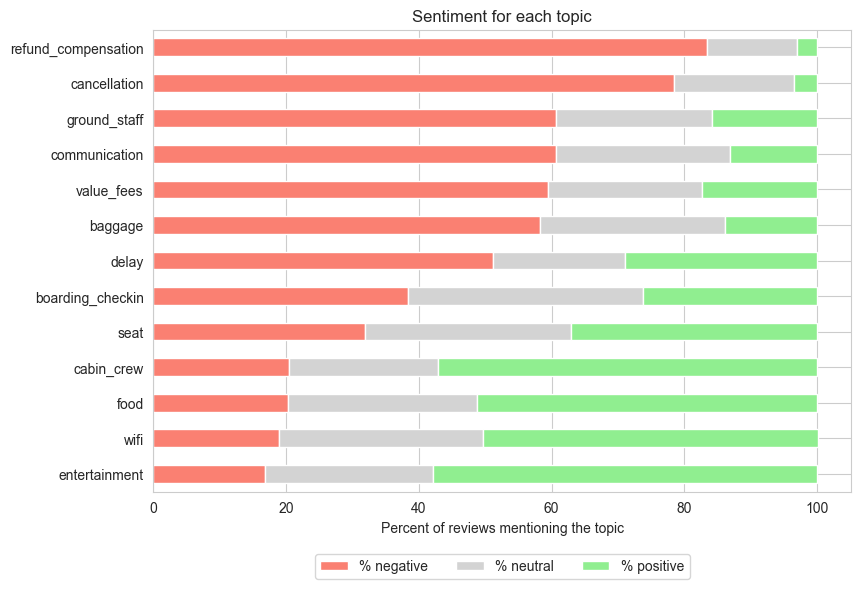

In [15]:
plot_data = summary[["% negative", "% neutral", "% positive"]]
plot_data.plot(kind="barh", stacked=True, figsize=(9, 6), color=["salmon", "lightgrey", "lightgreen"])
plt.title("Sentiment for each topic")
plt.xlabel("Percent of reviews mentioning the topic")
plt.ylabel("")
plt.gca().invert_yaxis()
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.show()

**Observations**

- **Refund / compensation** (83% negative) and **cancellation** (79% negative) are the most negative topics. Almost nobody writes positively about them.
- **Ground staff, communication, value and fees, and baggage** come next, with 58% to 61% of the mentions negative.
- **Entertainment, cabin crew, food and WiFi** are the most positive topics (50% to 58% positive), so passengers like what happens inside the plane more than what happens on the ground.
- **Delay** is mixed: about half negative, but also 29% positive. This is because phrases like "on time" are counted as mentions of the delay topic as well.
- Cabin crew and food are mentioned very often (38% and 47% of all reviews) but mostly in a positive or neutral way, while refund and cancellation are mentioned less often but almost always negatively.

Limits of this method: the topics are found with word lists, so a word can be matched in the wrong sense (for example "4 seats left" in a booking sentence is counted as a seat comment), and indirect complaints without topic words are missed.

## 10. Saving the results

In [16]:
pieces[["review_id", "topic", "text", "vader", "learned", "split"]].to_csv("data/aspect_segments.csv", index=False)
topic_scores.to_csv("data/aspect_reviews.csv", index=False)
print("saved", len(pieces), "pieces and", len(topic_scores), "review-topic scores")

saved 392624 pieces and 231583 review-topic scores


## Summary

- Reviews were split into about 590,000 sentences and clauses, and 392,624 pieces were matched to one of the 13 topics (62,454 of the 64,331 reviews have at least one topic).
- Each piece got a sentiment score from VADER and from the learned lexicon (the Logistic Regression model from Notebook 4).
- The learned model understands airline problems like "delayed", "cancelled" and "lost luggage" better than VADER.
- Cut-offs of 0.35 and 0.65 were chosen using the training reviews, and give about 90% agreement with the passengers' own ratings.
- The most negative topics are refund / compensation, cancellation, ground staff, communication, value and baggage. The most positive are entertainment, cabin crew, food and WiFi.

The results are saved in `data/aspect_segments.csv` (every piece with its scores) and `data/aspect_reviews.csv` (one row per review and topic).

Next notebook: validation, which checks the topic scores against the passengers' own ratings on the test reviews.